# 02 卷积、降噪与梯度边缘
先手算 3×3 核，再在真实图像上比较均值、高斯、中值和双边滤波，最后观察梯度与 Canny。
降噪输出仍是强度图；梯度和边缘输出描述的是变化，任务不同。


In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists()), None)
if root is None:
    raise RuntimeError("请在完整的 cv-beginner-course 项目里打开 Notebook")
if str(root) not in sys.path: sys.path.insert(0, str(root))
from course_utils import setup, device, show_images, save_figure, ROOT
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print("计算设备:", device())


计算设备: cuda


## 1 一个可手算的窗口
输入矩阵 a 的行、列对应图像 y、x 位置；每个数值是一处灰度强度。3×3 核矩阵每个元素为 1/9，输出等于窗口中9个像素乘权重后的和。奇数窗口 k 的下标范围为 −(k−1)/2 到 +(k−1)/2。下面手算中心像素，并与完整输出矩阵对应位置核对。


输入:
 [[ 0.  1.  2.  3.  4.]
 [ 5.  6.  7.  8.  9.]
 [10. 11. 12. 13. 14.]
 [15. 16. 17. 18. 19.]
 [20. 21. 22. 23. 24.]] 
核:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]] 
中心输出: 12.0 
全部输出:
 [[ 2.         2.6666665  3.6666665  4.6666665  5.3333335]
 [ 5.3333335  6.         7.0000005  8.         8.666667 ]
 [10.333333  11.000001  12.000001  13.        13.666666 ]
 [15.333333  16.        17.        18.        18.666666 ]
 [18.666666  19.333334  20.333332  21.333332  22.       ]]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20837 (\N{CJK UNIFIED IDEOGRAPH-5165}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 22343 (\N{CJK UNIFIED IDEOGRAPH-5747}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 36755 (\N{CJK UNIFIED IDEOGRAPH-8F93}) missing from font(s) DejaVu Sans.
 

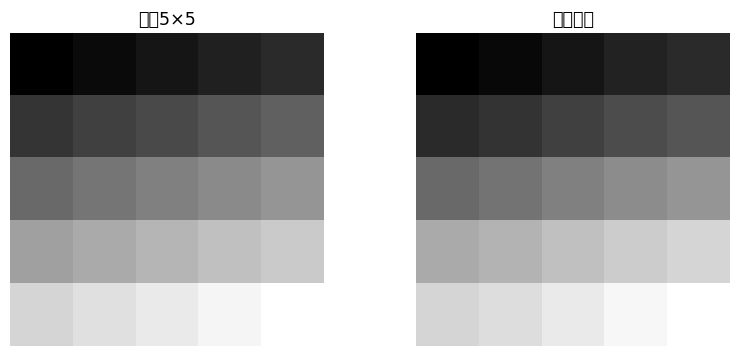

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/02_convolution_matrix.png')

In [2]:
a=np.arange(25,dtype=np.float32).reshape(5,5)
kernel=np.ones((3,3),np.float32)/9
center=float((a[1:4,1:4]*kernel).sum())
filtered=cv2.filter2D(a,-1,kernel,borderType=cv2.BORDER_REFLECT)
print("输入:\n",a,"\n核:\n",kernel,"\n中心输出:",center,"\n全部输出:\n",filtered)
assert np.isclose(center,filtered[2,2])
show_images([a,filtered],["输入5×5","均值输出"]); save_figure("02_convolution_matrix")


## 2 输入真实图片，再加入可控噪声
噪声在课程中人为添加，因此有干净参考图，可以计算 MSE/PSNR。真实照片本身没有无噪声真值时，不应虚构 PSNR。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 24178 (\N{CJK UNIFIED IDEOGRAPH-5E72}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 20928 (\N{CJK UNIFIED IDEOGRAPH-51C0}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 32771 (\N{CJK UNIFIED IDEOGRAPH-8003}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 22122 (\N{CJK UNIFIED IDEOGRAPH-566A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 22768 (\N{CJK UNIFIED IDEOGRAPH-58F0}) missing from font(s) DejaVu Sans.
 

/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 26031 (\N{CJK UNIFIED IDEOGRAPH-65AF}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 21452 (\N{CJK UNIFIED IDEOGRAPH-53CC}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 36793 (\N{CJK UNIFIED IDEOGR

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24178 (\N{CJK UNIFIED IDEOGRAPH-5E72}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20928 (\N{CJK UNIFIED IDEOGRAPH-51C0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21442 (\N{CJK UNIFIED IDEOGRAPH-53C2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32771 (\N{CJK UNIFIED IDEOGRAPH-8003}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

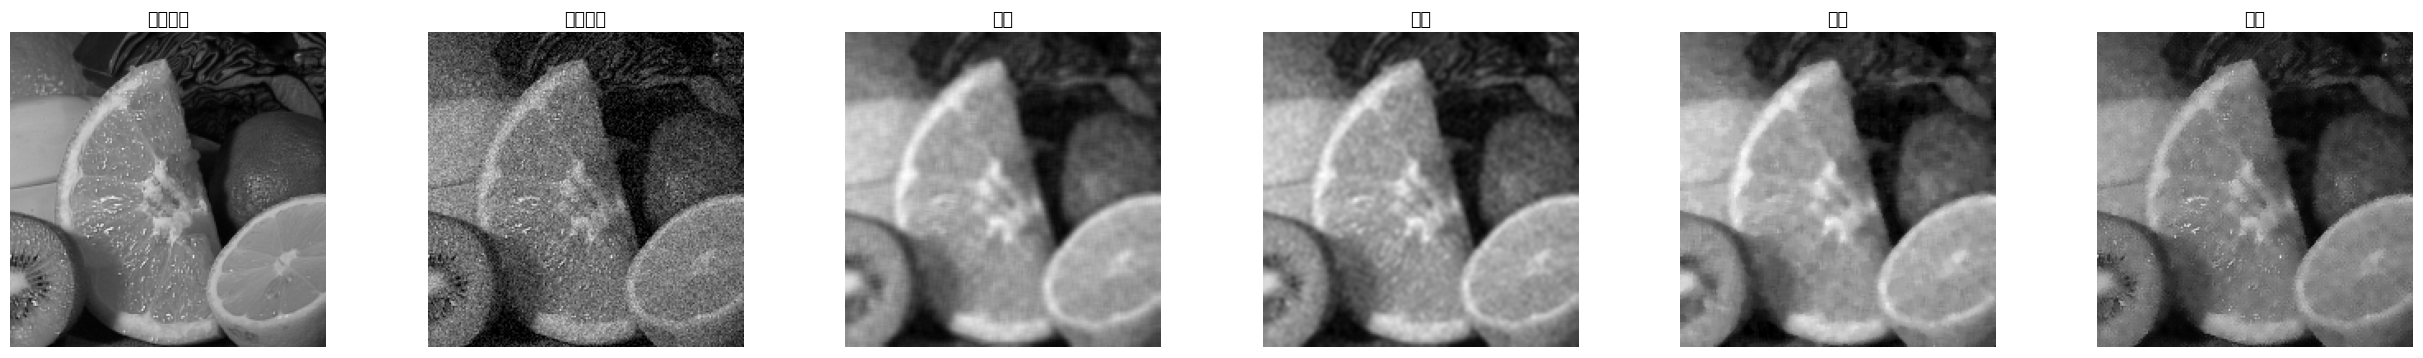

噪声输入 MSE= 308.55 PSNR= 23.24
均值 MSE= 129.74 PSNR= 27.0
高斯 MSE= 102.88 PSNR= 28.01
中值 MSE= 129.71 PSNR= 27.0
双边 MSE= 83.92 PSNR= 28.89


In [3]:
bgr=cv2.imread(str(ROOT/"assets/photos/fruits.jpg")); assert bgr is not None
clean=cv2.resize(cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),(192,192))
rng=np.random.default_rng(42)
noisy=np.clip(clean.astype(float)+rng.normal(0,18,clean.shape),0,255).astype(np.uint8)
results={"干净参考":clean,"噪声输入":noisy,"均值":cv2.blur(noisy,(5,5)),
         "高斯":cv2.GaussianBlur(noisy,(5,5),1.2),"中值":cv2.medianBlur(noisy,5),
         "双边":cv2.bilateralFilter(noisy,7,35,35)}
show_images(results); save_figure("02_denoising_comparison")
for name,img in list(results.items())[1:]:
    mse=np.mean((img.astype(float)-clean.astype(float))**2)
    print(name,"MSE=",round(mse,2),"PSNR=",round(10*np.log10(255**2/max(mse,1e-12)),2))


## 3 Sobel 梯度的数值意义
保留浮点有符号梯度，不能先转 uint8 丢掉负值。幅值 sqrt(gx²+gy²) 表示变化强度，方向 atan2(gy,gx)。


gx局部矩阵:
 [[ 16.  39.  87.  84.  22.]
 [ 29.  46.  67.  46. -12.]
 [ 33.  50.  49.  14. -42.]
 [ 35.  55.  26. -21. -56.]
 [ 37.  44. -12. -58. -80.]] 
幅值:
 [[ 66.   84.5 113.6  95.8  24.2]
 [ 65.7  82.1  88.   52.8  15.6]
 [ 35.5  51.4  49.8  17.2  55.3]
 [ 35.1  56.1  26.3  47.9  86.6]
 [ 53.8  49.2  17.   75.3 117.5]]


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 26799 (\N{CJK UNIFIED IDEOGRAPH-68AF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 26377 (\N{CJK UNIFIED IDEOGRAPH-6709}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 31526 (\N{CJK UNIFIED IDEOGRAPH-7B26}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 21495 (\N{CJK UNIFIED IDEOGRAPH-53F7}) missing from font(s) DejaVu Sans.
 

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26799 (\N{CJK UNIFIED IDEOGRAPH-68AF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26377 (\N{CJK UNIFIED IDEOGRAPH-6709}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

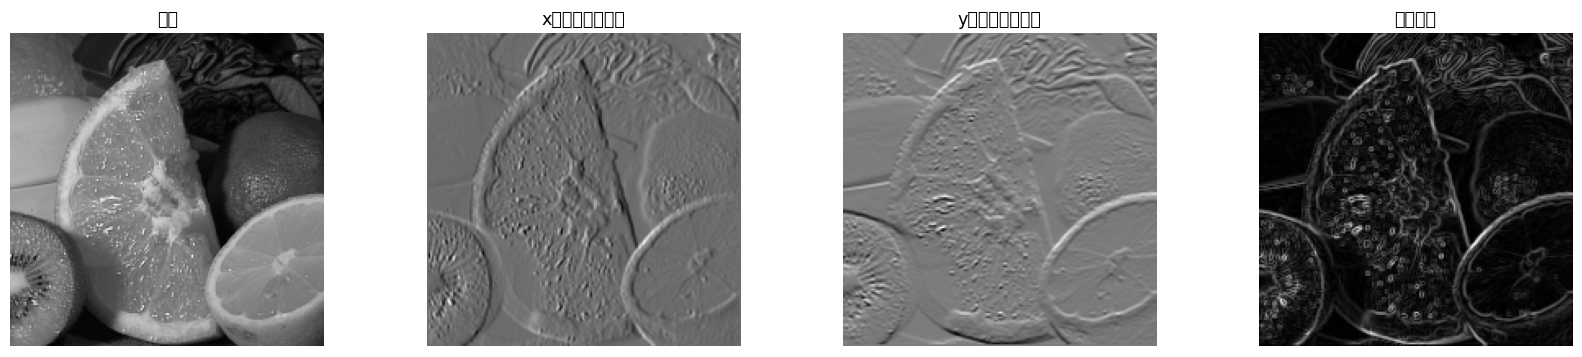

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/02_sobel.png')

In [4]:
gx=cv2.Sobel(clean,cv2.CV_32F,1,0,ksize=3)
gy=cv2.Sobel(clean,cv2.CV_32F,0,1,ksize=3)
magnitude=cv2.magnitude(gx,gy)
print("gx局部矩阵:\n",gx[50:55,50:55],"\n幅值:\n",magnitude[50:55,50:55].round(1))
show_images([clean,gx,gy,magnitude],["输入","x梯度（有符号）","y梯度（有符号）","梯度幅值"])
save_figure("02_sobel")


## 4 Canny：模糊、梯度、非极大值抑制与双阈值连接
这里调用 OpenCV 实现，修改阈值比较保留的边缘。它输出二值边缘，不是灰度降噪结果。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


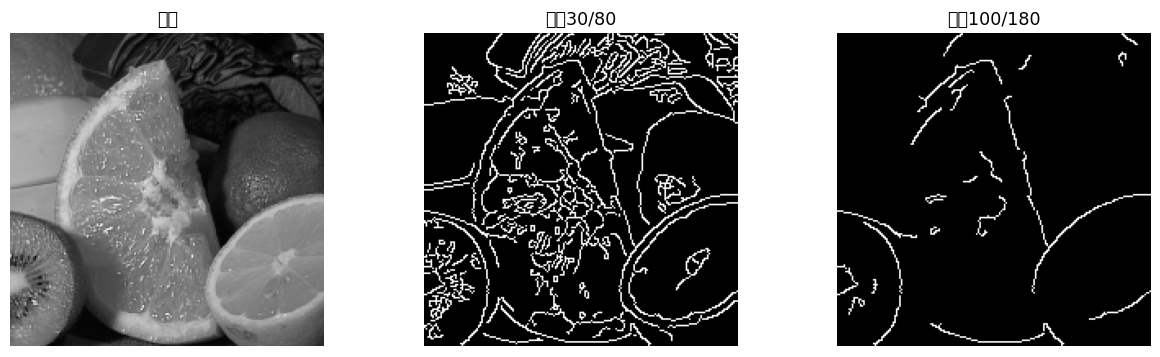

边缘像素数: 5060 1027


In [5]:
smooth=cv2.GaussianBlur(clean,(5,5),1)
e1=cv2.Canny(smooth,30,80); e2=cv2.Canny(smooth,100,180)
show_images([clean,e1,e2],["输入","阈值30/80","阈值100/180"]); save_figure("02_canny")
print("边缘像素数:",np.count_nonzero(e1),np.count_nonzero(e2))
assert set(np.unique(e1)).issubset({0,255})


## 5 参数实验与常见错误
比较核 3/5/9：降噪更强是否同时损失边缘？给图片加入椒盐噪声后再比较中值和高斯。
不要把“某图PSNR更高”推广成所有场景最优；不要把 Canny 和自适应阈值当成同一种算法。
参考：[OpenCV 平滑](https://docs.opencv.org/4.x/d4/d13/tutorial_py_filtering.html)、[梯度](https://docs.opencv.org/4.x/d5/d0f/tutorial_py_gradients.html)、[Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html)。
